# Comparison: Clean-trained vs Noise-trained DQN

Compare robustness under Gaussian observation noise. Both models evaluated with the same seeds (0-99) and same noise RNG. The noise-trained model was trained with episode-wise Gaussian noise in σ ∈ [0, 0.01].

## Recompute both sweeps

## 2. Load models and run sweeps

In [2]:
import gymnasium
import highway_env
from stable_baselines3 import DQN

# Load models
model_clean = DQN.load("../01_highway_dqn/artifacts/model.zip")
model_noise = DQN.load("artifacts/model.zip")

env = gymnasium.make("highway-fast-v0")

sigmas = np.concatenate([
    np.linspace(0.0, 0.01, 11),
    np.linspace(0.012, 0.03, 10),
    np.linspace(0.035, 0.06, 6),
    np.array([0.075, 0.09, 0.12, 0.15])
]).round(4).tolist()

rng = np.random.RandomState(1234)
N = 100

def eval_with_noise(model, sigmas, rng, N):
    results = []
    for sigma in sigmas:
        rets, lens, crashes = [], [], []
        for episode in range(N):
            obs, info = env.reset(seed=episode)
            done = truncated = False
            ep_ret = 0.0
            steps = 0
            crashed = False
            while not (done or truncated):
                if sigma > 0:
                    obs_noisy = obs + rng.randn(*obs.shape) * sigma
                else:
                    obs_noisy = obs
                action, _ = model.predict(obs_noisy, deterministic=True)
                obs, reward, done, truncated, info = env.step(action)
                ep_ret += reward
                steps += 1
                crashed = crashed or info.get("crashed", False)
            rets.append(ep_ret)
            lens.append(steps)
            crashes.append(crashed)
        results.append({
            'sigma': float(sigma),
            'mean_return': float(np.mean(rets)),
            'mean_length': float(np.mean(lens)),
            'crash_rate': float(np.mean(crashes)),
        })
    return results

res_clean = eval_with_noise(model_clean, sigmas, rng, N)
rng2 = np.random.RandomState(1234)
res_noise = eval_with_noise(model_noise, sigmas, rng2, N)

df_clean = pd.DataFrame(res_clean)
df_noise = pd.DataFrame(res_noise)
env.close()
df_clean.head()


objc[52678]: Class SDL_RumbleMotor is implemented in both /opt/homebrew/Cellar/sdl2/2.32.10/lib/libSDL2-2.0.0.dylib (0x110ffc138) and /Users/frederikbach/models/.venv/lib/python3.14/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x1114fc9c8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[52678]: Class SDL_RumbleContext is implemented in both /opt/homebrew/Cellar/sdl2/2.32.10/lib/libSDL2-2.0.0.dylib (0x110ffc188) and /Users/frederikbach/models/.venv/lib/python3.14/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x1114fca18). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[52678]: Class SDLApplication is implemented in both /opt/homebrew/Cellar/sdl2/2.32.10/lib/libSDL2-2.0.0.dylib (0x110ffbc88) and /Users/frederikbach/models/.venv/lib/python3.14/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x1114fca68). This may cause spurious casting

,sigma,mean_return,mean_length,crash_rate
0,0.000,19.720233,24.68,0.32
1,0.001,19.722682,24.72,0.33
2,0.002,20.108737,25.19,0.32
3,0.003,20.457444,25.57,0.28
4,0.004,20.248680,25.36,0.29


## Comparison plots

## 3. Comparison plots

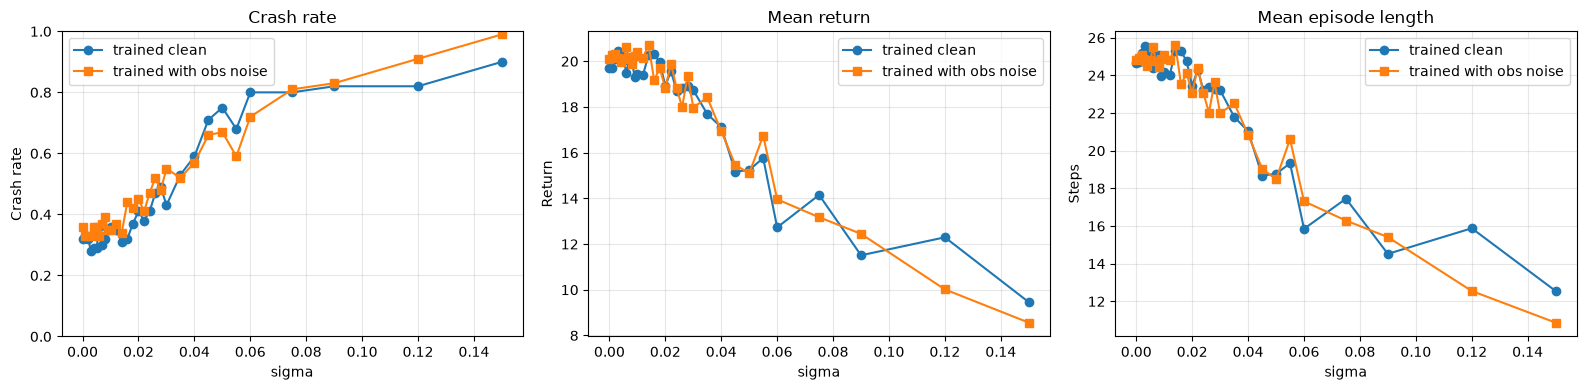

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(df_clean["sigma"], df_clean["crash_rate"], marker='o', label='trained clean')
axes[0].plot(df_noise["sigma"], df_noise["crash_rate"], marker='s', label='trained with obs noise')
axes[0].set_title("Crash rate")
axes[0].set_xlabel("sigma"); axes[0].set_ylabel("Crash rate")
axes[0].set_ylim(0,1); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(df_clean["sigma"], df_clean["mean_return"], marker='o', label='trained clean')
axes[1].plot(df_noise["sigma"], df_noise["mean_return"], marker='s', label='trained with obs noise')
axes[1].set_title("Mean return")
axes[1].set_xlabel("sigma"); axes[1].set_ylabel("Return")
axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(df_clean["sigma"], df_clean["mean_length"], marker='o', label='trained clean')
axes[2].plot(df_noise["sigma"], df_noise["mean_length"], marker='s', label='trained with obs noise')
axes[2].set_title("Mean episode length")
axes[2].set_xlabel("sigma"); axes[2].set_ylabel("Steps")
axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()
